# **Logistic Regression**

The perceptron answers **yes or no**. Logistic regression answers **how sure**: a probability between 0 and 1.
It starts the same way (a weighted sum z), and it is just another classifier you can pick in scikit-learn.

1. The S-curve
2. Example: will a student pass?
3. Perceptron or logistic regression?

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## 1. The S-curve
The perceptron says 1 if z > 0, else 0. Logistic regression puts z through an S-shaped curve (the **sigmoid**),
which turns any number into a probability between 0 and 1.

$$p = \frac{1}{1 + e^{-z}}$$

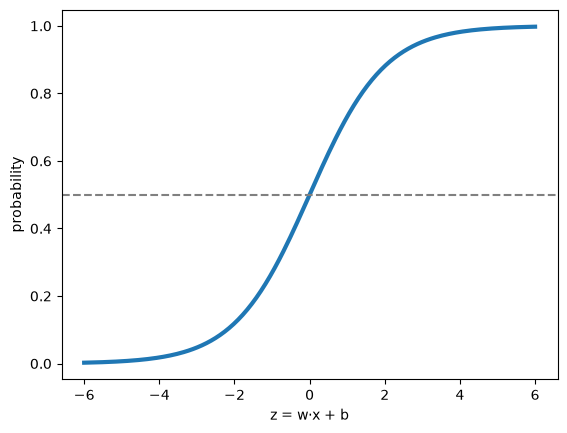

z = -4 -> p = 0.02
z = -2 -> p = 0.12
z =  0 -> p = 0.50
z =  2 -> p = 0.88
z =  4 -> p = 0.98


In [13]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-6, 6, 200)
plt.plot(z, sigmoid(z), lw=3)
plt.axhline(0.5, ls="--", c="gray")
plt.xlabel("z = w·x + b")
plt.ylabel("probability")
plt.show()

for z_value in [-4, -2, 0, 2, 4]:
    print(f"z = {z_value:2d} -> p = {sigmoid(z_value):.2f}")

## 2. Example: will a student pass?
60 students: hours studied, and passed (1) or failed (0).

In [21]:
rng = np.random.default_rng(3)
hours = np.round(rng.uniform(0, 10, 60), 1)
passed = (rng.random(60) < sigmoid(1.1 * (hours - 5))).astype(int)

model = LogisticRegression() # import from sklearn
model.fit(hours.reshape(-1, 1), passed)

for h in [2, 4, 5, 6, 8, 10]:
    print(f"{h} hours -> {model.predict_proba([[h]])[0, 1]:.0%} chance to pass")

2 hours -> 2% chance to pass
4 hours -> 19% chance to pass
5 hours -> 46% chance to pass
6 hours -> 76% chance to pass
8 hours -> 98% chance to pass
10 hours -> 100% chance to pass


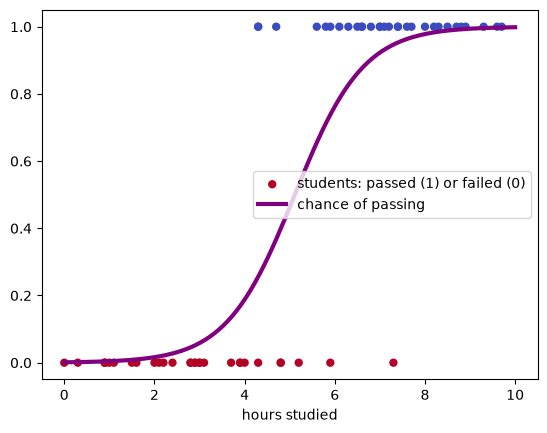

In [22]:
hh = np.linspace(0, 10, 200).reshape(-1, 1)
plt.scatter(hours, passed, c=passed, cmap="coolwarm_r", s=25, label="students: passed (1) or failed (0)")
plt.plot(hh, model.predict_proba(hh)[:, 1], c="purple", lw=3, label="chance of passing")
plt.xlabel("hours studied")
plt.legend(loc="center right")
plt.show()

The **dots** are what happened: an exam is passed or failed, so they are at 0 or 1.
The **curve** is the chance: about 3 out of 4 students who study 6 hours pass.

## 3. Perceptron or logistic regression?
Same real data as before (breast cancer, 30 features). Same code, only the model changes.

In [23]:
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3,
                                                    random_state=0, stratify=data.target)

for name, clf in [("Perceptron", Perceptron(random_state=0)),
                  ("Logistic regression", LogisticRegression())]:           
    m = make_pipeline(StandardScaler(), clf).fit(X_train, y_train)
    print(f"{name:20s} test accuracy {m.score(X_test, y_test):.1%}")

Perceptron           test accuracy 95.3%
Logistic regression  test accuracy 95.9%


Both draw a straight decision boundary, so the accuracy is similar. The big difference:
logistic regression can also tell us **how sure** it is.

In [24]:
logreg = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
probs = logreg.predict_proba(X_test[:5])                  # get the probabilities, not just 0/1

for p in probs:
    print(f"malignant {p[0]:.0%}   benign {p[1]:.0%}")

malignant 100%   benign 0%
malignant 13%   benign 87%
malignant 100%   benign 0%
malignant 1%   benign 99%
malignant 100%   benign 0%


**Why does that matter?** We can choose our own threshold. In cancer screening, a missed cancer is worse than a false alarm,
so we might say "cancer" already when the model is 10 % sure, instead of the default 50 %:

In [28]:
p_malignant = logreg.predict_proba(X_test)[:, 0]
truly_malignant = (y_test == 0)

for threshold in [0.5, 0.1]:
    says_cancer = p_malignant >= threshold
    missed = (~says_cancer & truly_malignant).sum()
    false_alarms = (says_cancer & ~truly_malignant).sum()
    print(f"threshold {threshold}: missed cancers {missed}, false alarms {false_alarms}")

threshold 0.5: missed cancers 3, false alarms 4
threshold 0.1: missed cancers 1, false alarms 11


## Summary
| | Perceptron | Logistic regression |
|---|---|---|
| Output | 0 or 1 | a probability |
| Boundary | straight line | straight line |
| Can choose the threshold? | no | yes |
| In scikit-learn | `Perceptron()` | `LogisticRegression()` |

Logistic regression is a common first choice for classification: simple, fast, and it tells you how sure it is.

⚠️ The medical example is for teaching only.